# Crystal-field tomography, small 3D toy, per-voxel sub-block multislice
A 3.2 nm FCC particle (twin pair plus an amorphous cap) tilted about y in 1 degree steps, imaged at 100 nm defocus without an aperture and binned to 2 A pixels. Each 2 A voxel holds a 7 x 7 x 7 block of fine potential (0.29 A). Every tenth tilt is held out. Inversions come from `run_ms3d.py`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
from scipy.ndimage import gaussian_filter

sys.path.insert(0, str(Path.cwd()))

from quantem.core.visualization.visualization import show_2d

import sim3d
from invert_ms3d import SubMS3, flicker_power, peak_fraction, true_object

## Data
The twin pair with the amorphous cap (`twinAm`) and without it (`twin`). `I_nobragg` is the same sample with every slice low-passed below 0.25 / A, so it has no flicker.

In [2]:
sim3d.main("twinAm")
sim3d.main("twin")
sims = {kind: np.load(f"runs/sim_{kind}.npz") for kind in ["twinAm", "twin"]}
cases = {
    "mean potential only": "coarse",
    "sub-blocks, U >= 0": "positive",
    "sub-blocks, U >= -0.8 density": "floor08",
}
res = {kind: {n: np.load(f"runs/ms_{kind}_{c}.npz") for n, c in cases.items()} for kind in sims}

twinAm: 957 atoms, multislice 16.8 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_3d/runs/sim_twinAm.npz


twin: 959 atoms, multislice 15.9 s -> /Users/cophus/Library/CloudStorage/Dropbox/python/quantem/tomography/crystal_field_3d/runs/sim_twin.npz


## Forward model at the true potential
True atoms on the 7 x 7 x 7 sub-blocks, all tilts.

In [3]:
truth = {}
for kind, d in sims.items():
    m = SubMS3(json.loads(str(d["cfg"])), d["angles"])
    U = true_object(d, m)
    with torch.no_grad():
        pred = torch.cat([m.forward(torch.arange(i, min(i + 12, 180)), U) for i in range(0, 180, 12)]).numpy()
    truth[kind] = dict(U=U.numpy(), pred=pred, vbar=m.coarse(U).numpy())

## Scores
Image error over the central 36 x 36 pixels, normalised by the data variance, on train and held-out tilts. Density correlation with the true mean potential (raw and after a 1-voxel Gaussian blur) and mean density inside the particle relative to the truth. The no-Bragg row compares the flicker-free images with the data.

In [4]:
for kind, d in sims.items():
    data = d["I_coarse"]
    c = slice(6, 42)
    var = data[:, c, c].var()
    held = np.arange(5, len(data), 10)
    train = np.setdiff1d(np.arange(len(data)), held)
    part = d["occ"].sum(0) > 0.9
    vt = d["vbar"]
    e = ((d["I_nobragg"] - data)[:, c, c] ** 2).mean((1, 2)) / var
    print(kind)
    print(f"  {'no Bragg (oracle images)':30s} train {e[train].mean():.4f}  held-out {e[held].mean():.3f}")
    for name, r in {"true potential": truth[kind], **res[kind]}.items():
        e = ((r["pred"] - data)[:, c, c] ** 2).mean((1, 2)) / var
        vb = r["vbar"]
        line = f"  {name:30s} train {e[train].mean():.4f}  held-out {e[held].mean():.3f}"
        line += f"  density corr {np.corrcoef(vb.ravel(), vt.ravel())[0, 1]:.3f}"
        line += f" ({np.corrcoef(gaussian_filter(vb, 1).ravel(), gaussian_filter(vt, 1).ravel())[0, 1]:.3f})"
        line += f"  mean {vb[part].mean() / vt[part].mean():.2f}"
        print(line)

twinAm
  no Bragg (oracle images)       train 0.6667  held-out 0.690
  true potential                 train 0.0063  held-out 0.006  density corr 0.995 (1.000)  mean 1.00
  mean potential only            train 0.3574  held-out 0.376  density corr 0.782 (0.860)  mean 0.40
  sub-blocks, U >= 0             train 0.0370  held-out 0.052  density corr 0.931 (0.983)  mean 1.32
  sub-blocks, U >= -0.8 density  train 0.0242  held-out 0.037  density corr 0.946 (0.987)  mean 0.95
twin
  no Bragg (oracle images)       train 0.7193  held-out 0.740
  true potential                 train 0.0079  held-out 0.008  density corr 0.996 (1.000)  mean 1.00
  mean potential only            train 0.4389  held-out 0.450  density corr 0.742 (0.831)  mean 0.33
  sub-blocks, U >= 0             train 0.0408  held-out 0.059  density corr 0.954 (0.989)  mean 1.39
  sub-blocks, U >= -0.8 density  train 0.0277  held-out 0.043  density corr 0.966 (0.993)  mean 1.00


## All tilts through the particle centre, amorphous cap
The image row through the tilt axis centre (y = 0) at every tilt.

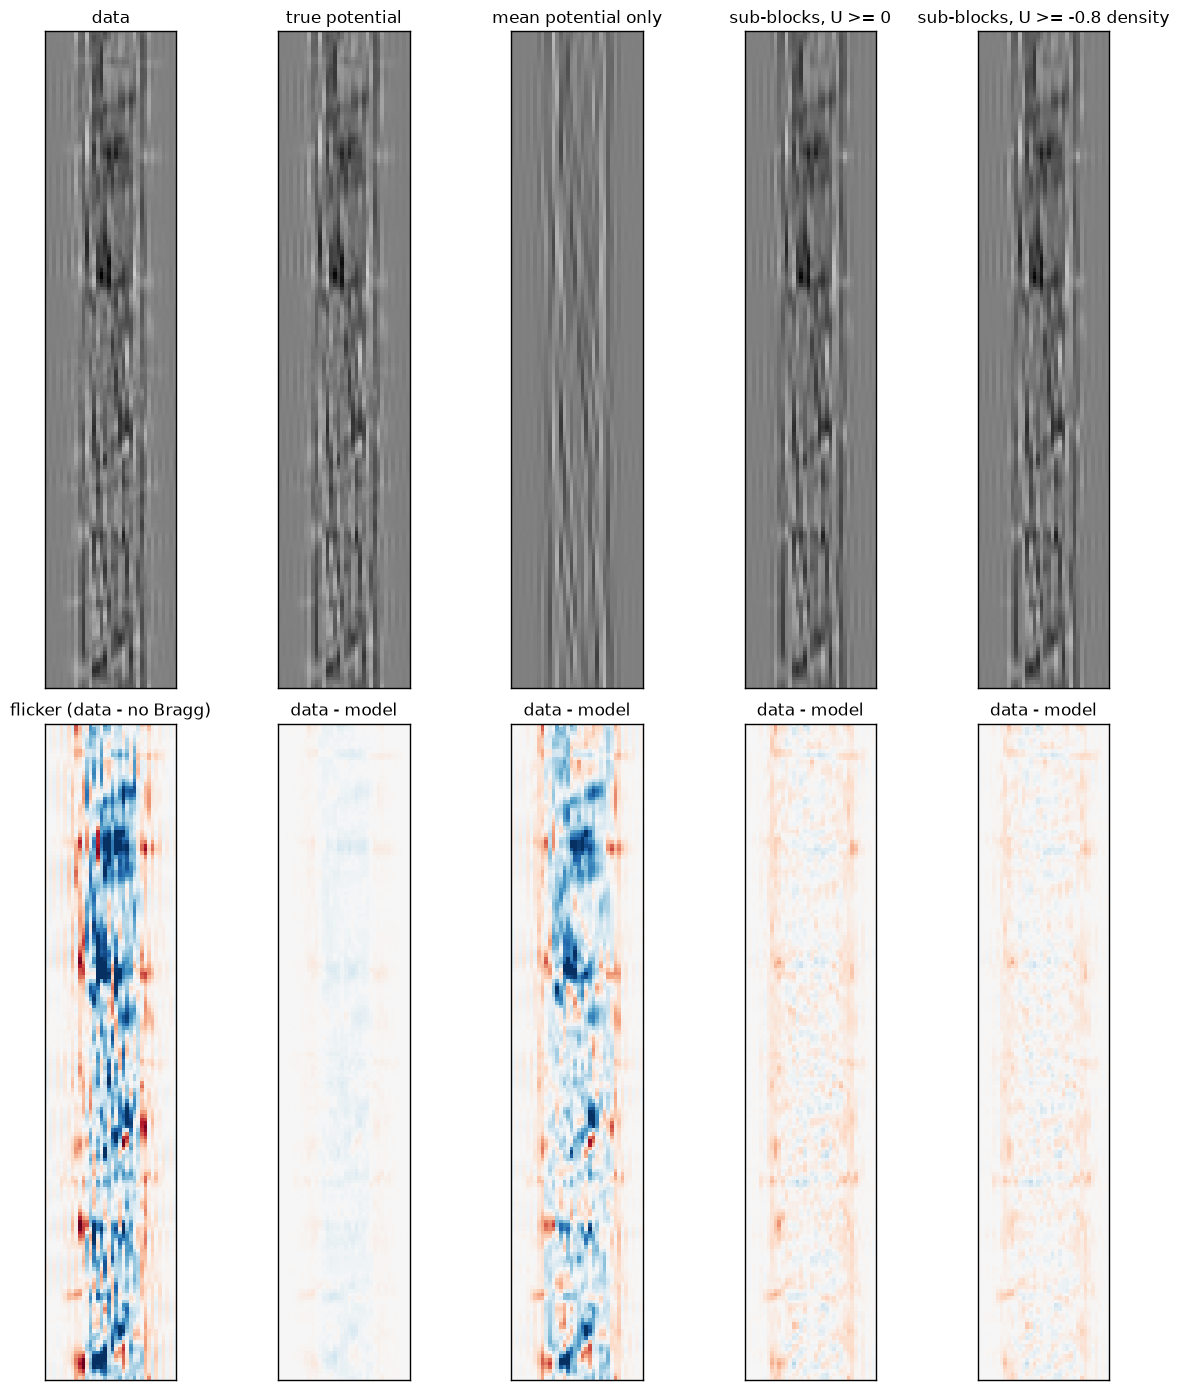

In [5]:
d = sims["twinAm"]
r = {"true potential": truth["twinAm"], **res["twinAm"]}
data = d["I_coarse"]
cols = list(r)
nc = len(cols) + 1
row = lambda a: a[:, 6:42, 24]
norm_int = {"interval_type": "manual", "vmin": 0.6, "vmax": 1.4}
norm_diff = {"interval_type": "centered", "half_range": 0.2}
show_2d(
    [
        [row(data)] + [row(r[n]["pred"]) for n in cols],
        [row(data) - row(d["I_nobragg"])] + [row(data) - row(r[n]["pred"]) for n in cols],
    ],
    norm=[[norm_int] * nc, [norm_diff] * nc],
    cmap=[["gray"] * nc, ["RdBu_r"] * nc],
    title=[["data"] + cols, ["flicker (data - no Bragg)"] + ["data - model"] * len(cols)],
    axsize=(2.5, 7),
);

## Held-out tilts, amorphous cap
Rows are tilts -45, -5, 35 and 75 degrees; the tilt axis is vertical.

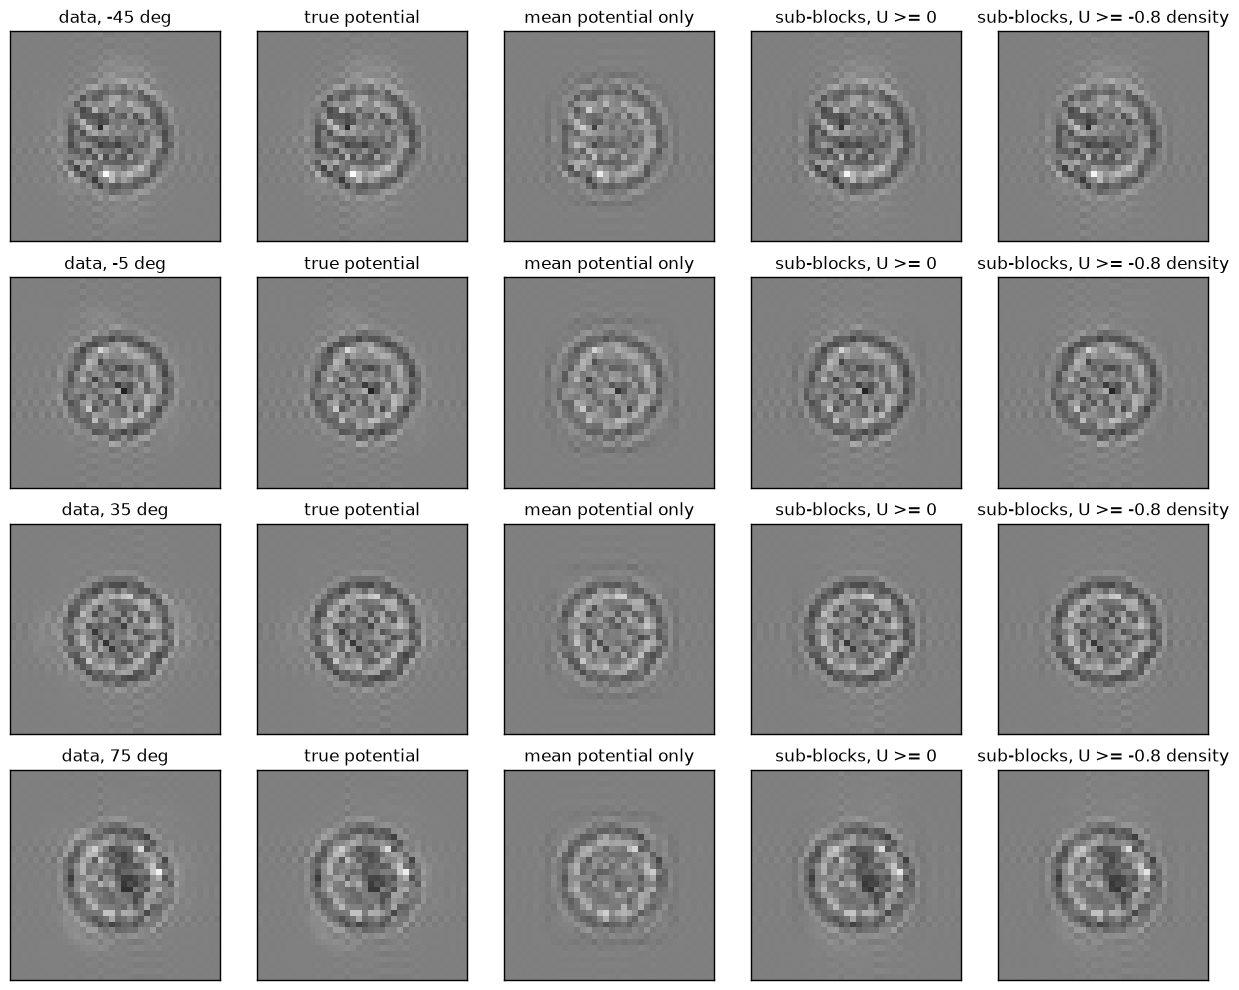

In [6]:
tilts = [45, 85, 125, 165]
img = lambda a, t: a[t, 6:42, 6:42].T
show_2d(
    [[img(data, t)] + [img(r[n]["pred"], t) for n in cols] for t in tilts],
    norm=norm_int,
    cmap="gray",
    title=[[f"data, {d['angles'][t]:.0f} deg"] + cols for t in tilts],
    axsize=(2.5, 2.5),
);

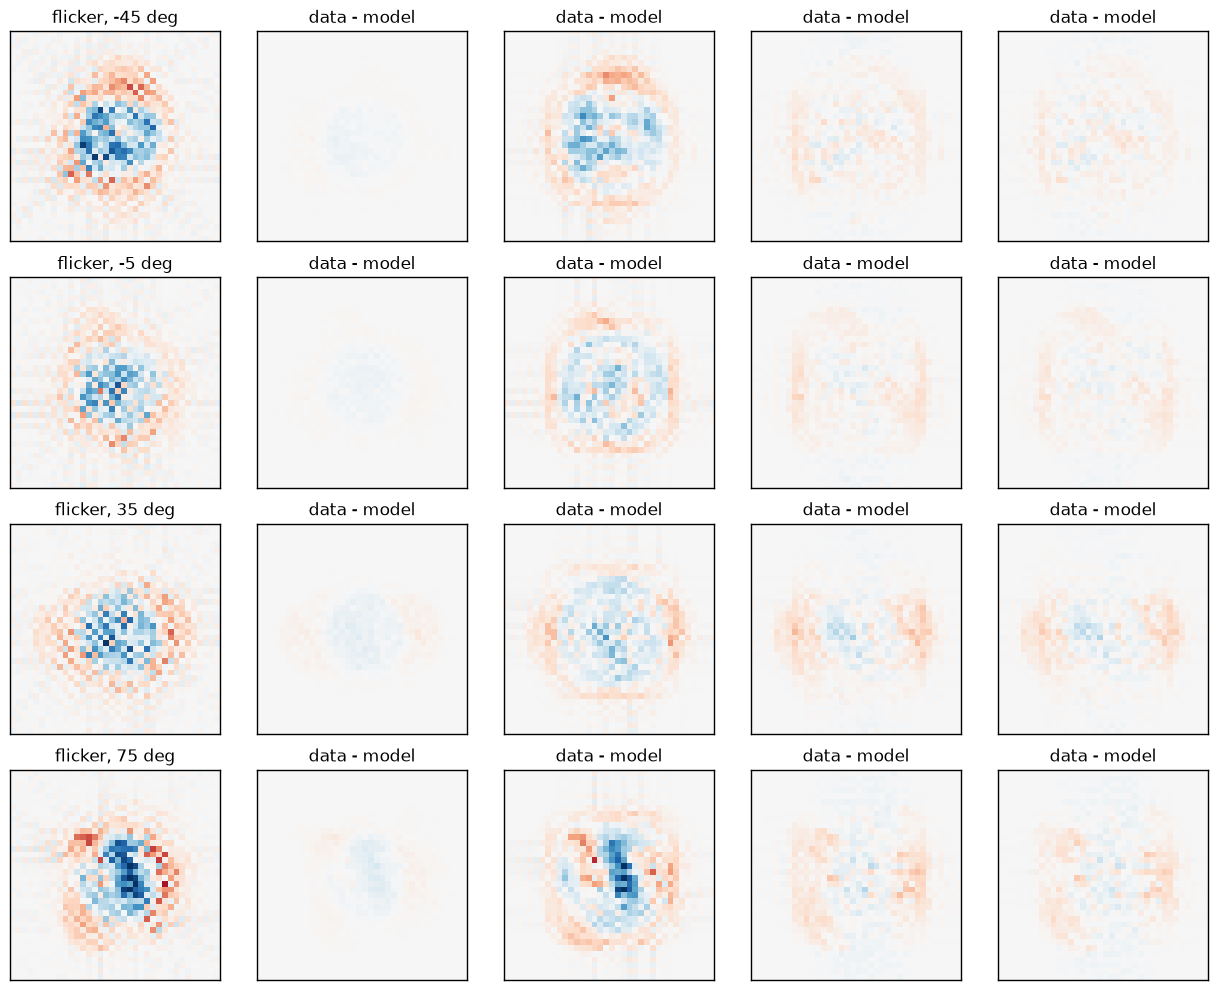

In [7]:
show_2d(
    [[img(data - d["I_nobragg"], t)] + [img(data - r[n]["pred"], t) for n in cols] for t in tilts],
    norm=norm_diff,
    cmap="RdBu_r",
    title=[[f"flicker, {d['angles'][t]:.0f} deg"] + ["data - model"] * len(cols) for t in tilts],
    axsize=(2.5, 2.5),
);

## Mean potential and flicker-term power, amorphous cap
Central slices normal to x, y and z. Flicker-term power: mean square of the part of U above the 2 A band, per voxel. The mean-potential-only model has none.

In [8]:
m = SubMS3(json.loads(str(d["cfg"])), d["angles"])
fp = {n: flicker_power(r[n]["U"], m) * (n != "mean potential only") for n in cols}
k = d["vbar"].shape[0] // 2
slices = lambda v: [v[k], v[:, k], v[:, :, k]]
labels = ["x = 0 (y, z)", "y = 0 (x, z)", "z = 0 (x, y)"]

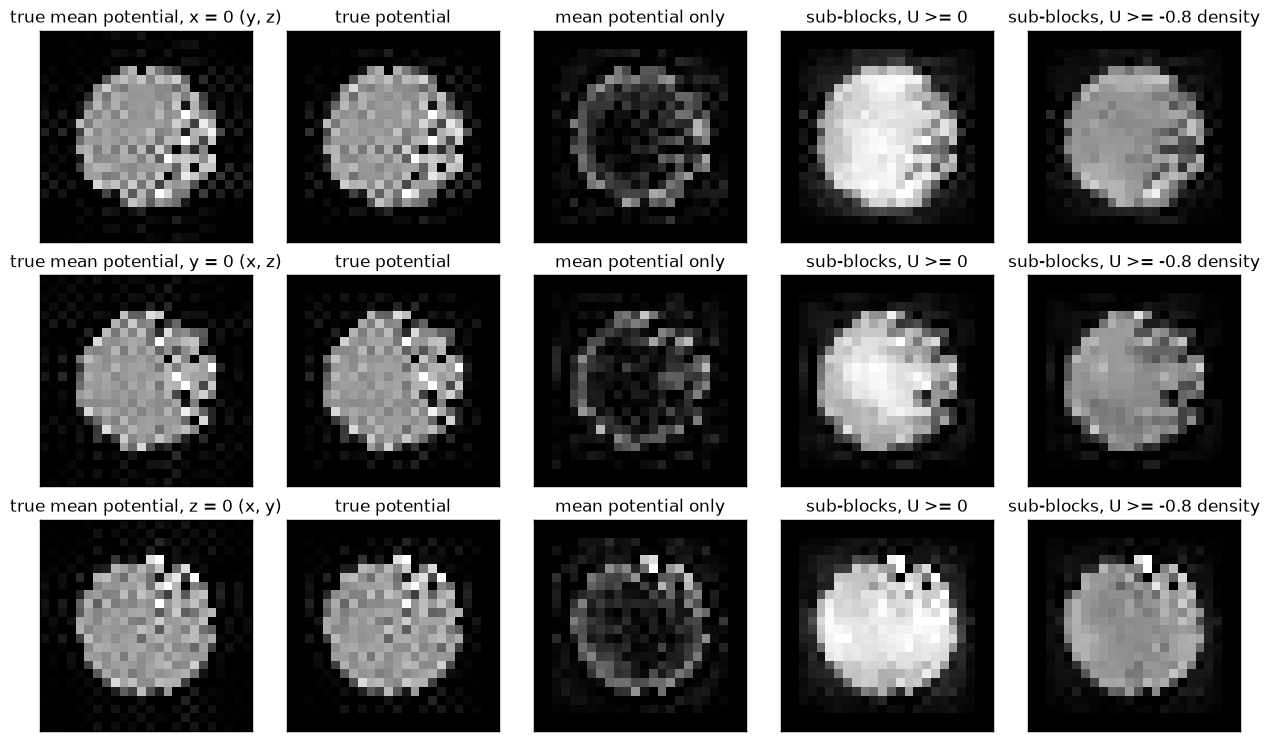

In [9]:
show_2d(
    [[s] + [slices(r[n]["vbar"])[i] for n in cols] for i, s in enumerate(slices(d["vbar"]))],
    norm={"interval_type": "manual", "vmin": 0.0, "vmax": 0.04},
    cmap="gray",
    title=[[f"true mean potential, {labels[i]}"] + cols for i in range(3)],
    axsize=(2.5, 2.5),
);

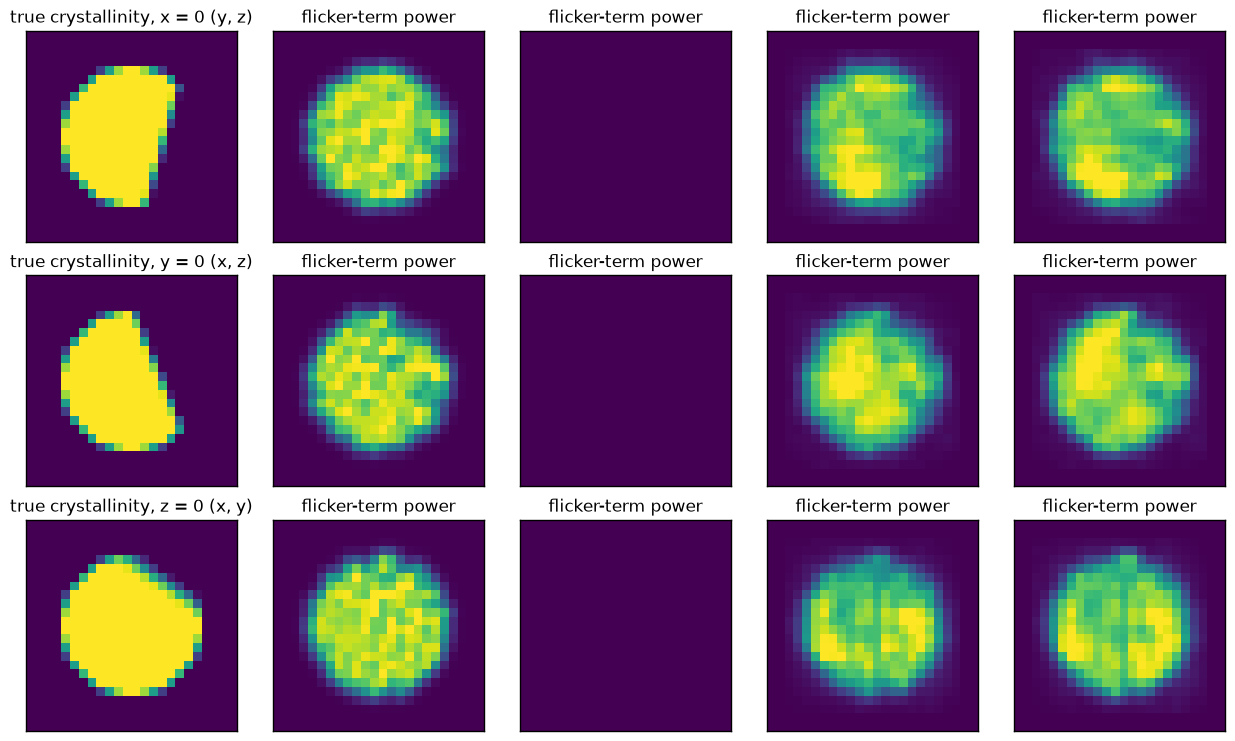

In [10]:
show_2d(
    [[s] + [slices(fp[n])[i] for n in cols] for i, s in enumerate(slices(d["cryst"]))],
    norm=[[{"interval_type": "manual", "vmin": 0.0, "vmax": 1.0}] + [{"interval_type": "quantile"}] * len(cols)] * 3,
    cmap="viridis",
    title=[[f"true crystallinity, {labels[i]}"] + ["flicker-term power"] * len(cols) for i in range(3)],
    axsize=(2.5, 2.5),
);

## Local order, amorphous cap
Peak fraction of the local 3D spectrum (8 A window, 0.3 to 1.4 / A) at 40 voxels inside the crystal and 40 inside the cap. Bragg peaks are points and amorphous scattering a shell, so the true potential separates them.

In [11]:
rng = np.random.default_rng(0)
s = slice(m.i0, m.i0 + m.nb)
vox = {}
for name, mask in [("crystal", d["cryst"][s, s, s] > 0.95), ("cap", d["occ"][2][s, s, s] > 0.95)]:
    v = np.argwhere(mask)
    vox[name] = v[rng.choice(len(v), 40, replace=False)]
for n in ["true potential"] + cols[2:]:
    pf = {k: peak_fraction(r[n]["U"], m, v).mean() for k, v in vox.items()}
    print(f"{n:30s} crystal {pf['crystal']:.3f}  cap {pf['cap']:.3f}")

true potential                 crystal 0.294  cap 0.192
sub-blocks, U >= 0             crystal 0.188  cap 0.190


sub-blocks, U >= -0.8 density  crystal 0.207  cap 0.204


## All tilts through the particle centre, no cap

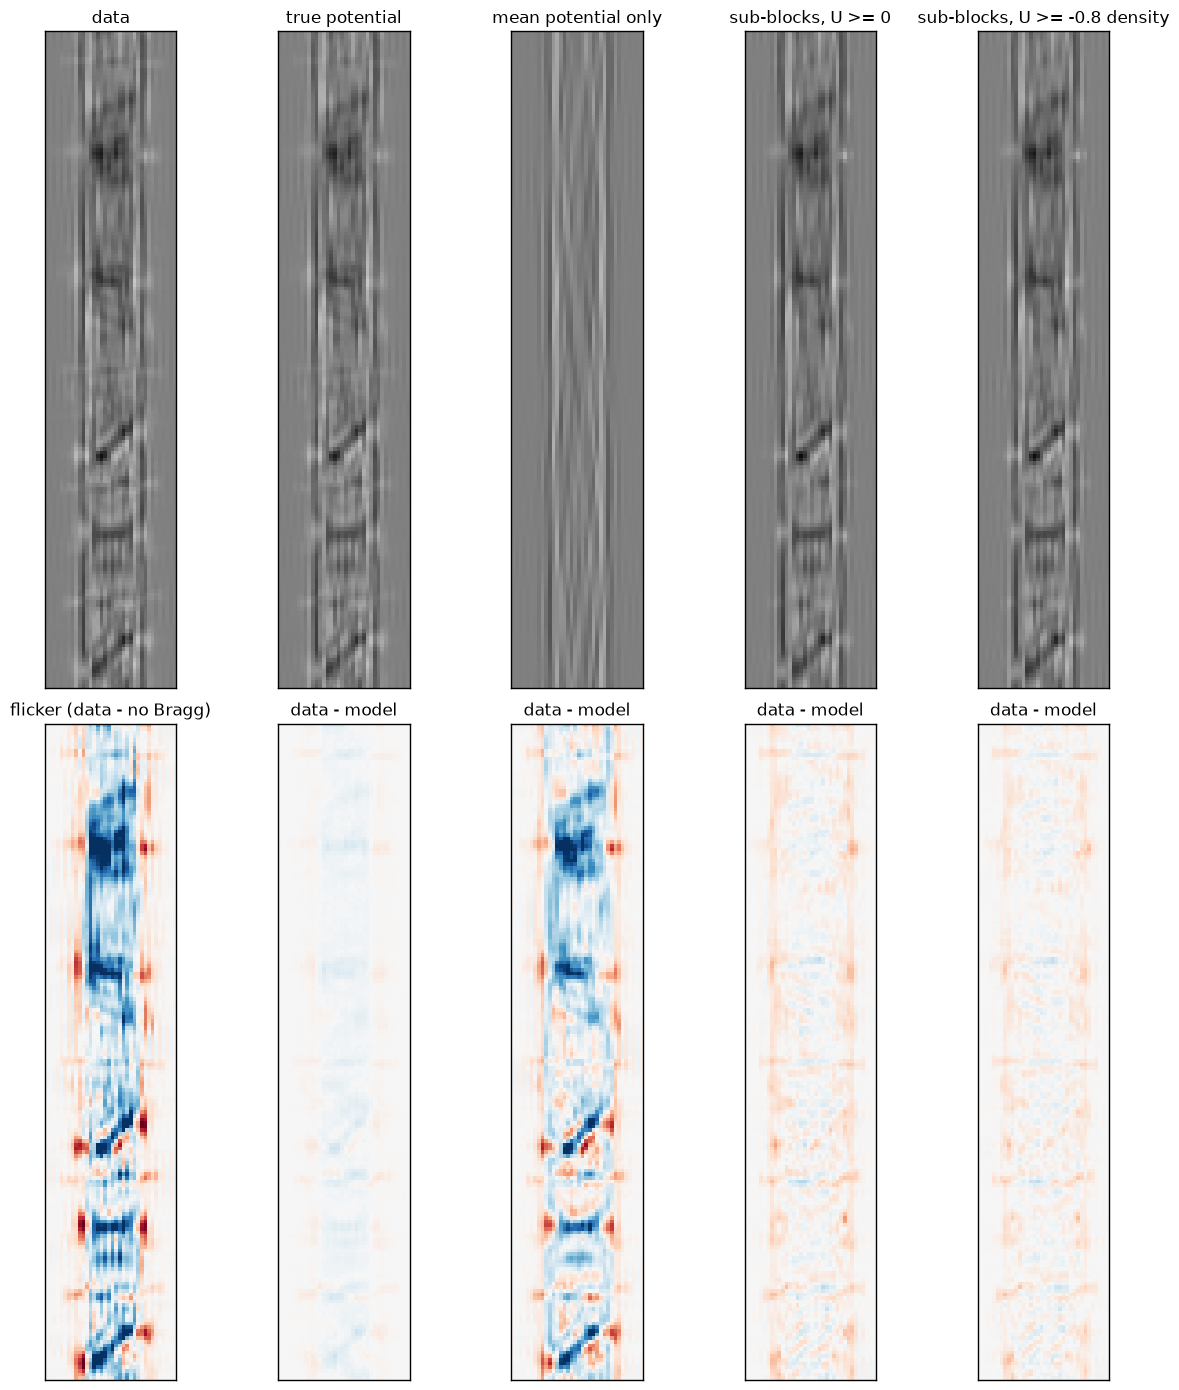

In [12]:
d = sims["twin"]
r = {"true potential": truth["twin"], **res["twin"]}
data = d["I_coarse"]
show_2d(
    [
        [row(data)] + [row(r[n]["pred"]) for n in cols],
        [row(data) - row(d["I_nobragg"])] + [row(data) - row(r[n]["pred"]) for n in cols],
    ],
    norm=[[norm_int] * nc, [norm_diff] * nc],
    cmap=[["gray"] * nc, ["RdBu_r"] * nc],
    title=[["data"] + cols, ["flicker (data - no Bragg)"] + ["data - model"] * len(cols)],
    axsize=(2.5, 7),
);

## Mean potential, no cap

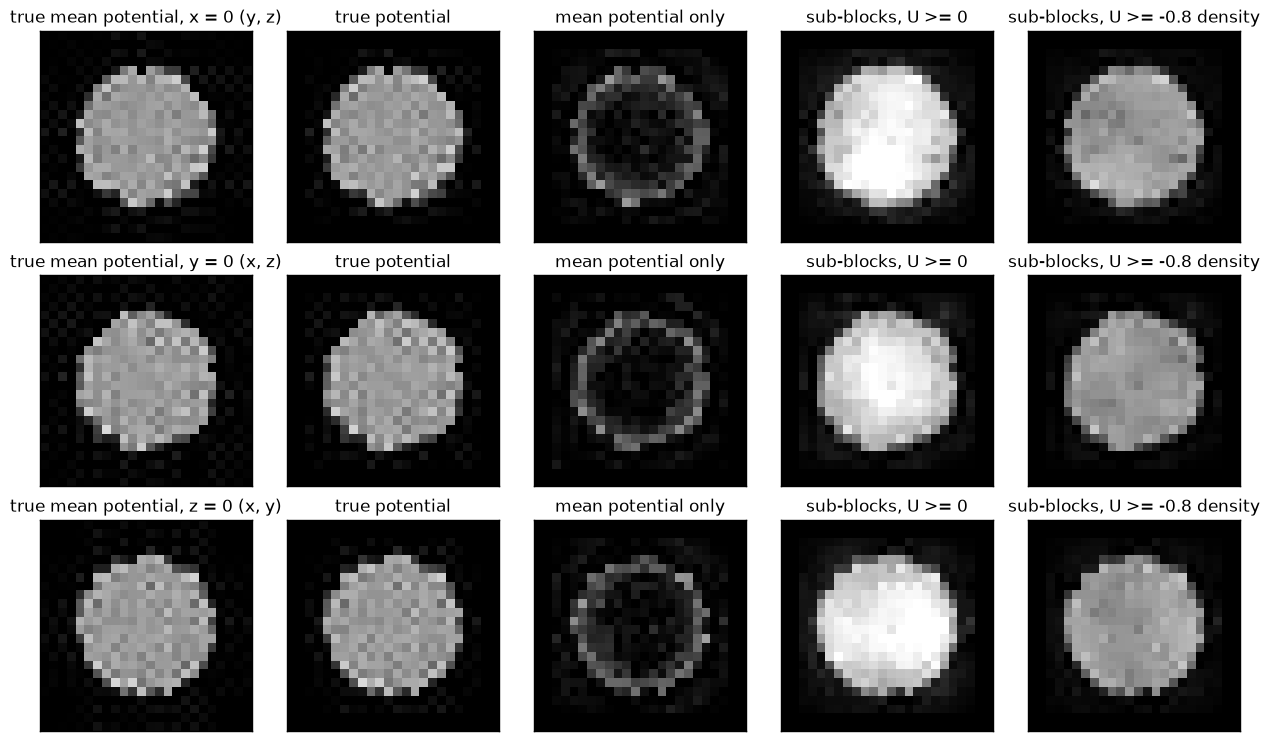

In [13]:
show_2d(
    [[s] + [slices(r[n]["vbar"])[i] for n in cols] for i, s in enumerate(slices(d["vbar"]))],
    norm={"interval_type": "manual", "vmin": 0.0, "vmax": 0.04},
    cmap="gray",
    title=[[f"true mean potential, {labels[i]}"] + cols for i in range(3)],
    axsize=(2.5, 2.5),
);